In [1]:
# 作业3：Explore a netCDF dataset

#数据读入和准备部分
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

# 读取数据，根据官方文档跳过有异常填充值的辅助变量time_bnds
ds = xr.open_dataset("precip.mon.mean.nc", drop_variables="time_bnds")
precip = ds["precip"].load()
ds.close()

# 将经度从0～360°转换为-180～180°，画全球图更规范一点
# 转换后重新排序，保证经度和纬度都从小到大排列
precip = precip.assign_coords(lon=((precip.lon + 180) % 360) - 180)
precip = precip.sortby("lon").sortby("lat")

print("开始、结束月份：", precip.time.dt.strftime("%Y-%m").values[[0, -1]])
print("数据形状（时间、纬度、经度）：", precip.shape)
print("单位：", precip.attrs["units"])
print("缺测值个数：", precip.isnull().sum().item())

# 选取格点中心位于指定经纬度范围内的数据（华南附近矩形区域）
region = precip.sel(lat=slice(20, 30), lon=slice(105, 120))

# 按面积计算每个月的区域平均降水率
# 规则经纬网格的面积正比于纬度余弦，cos的输入需要使用弧度
weights = np.cos(np.deg2rad(region.lat.astype("float64")))
regional_mean = region.weighted(weights).mean(dim=("lat", "lon"))

开始、结束月份： ['1979-01' '2026-06']
数据形状（时间、纬度、经度）： (570, 72, 144)
单位： mm/day
缺测值个数： 0


区域逐月多年平均（mm/day）：
month
1     1.661
2     2.362
3     3.404
4     5.071
5     7.193
6     9.008
7     6.773
8     6.780
9     4.778
10    2.794
11    2.123
12    1.238
Name: precip, dtype: float64
最大距平： 2024-04 4.738 mm/day
最小距平： 2004-06 -3.998 mm/day


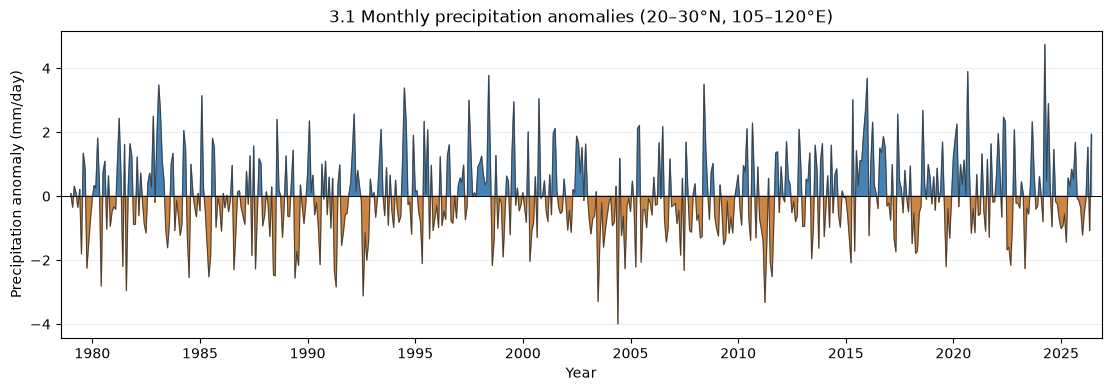

In [4]:
# 题目3.1：去除月季节循环并绘制时间序列

# 按日历月份分组，再沿时间平均，得到12个月的多年平均值
clim = regional_mean.groupby("time.month").mean(dim="time")

# 每个一月减去一月多年平均值，每个二月减去二月多年平均值……以此类推
anomaly = regional_mean.groupby("time.month") - clim

print("区域逐月多年平均（mm/day）：")
print(clim.to_series().round(3))

# 用idxmax()和idxmin()返回最大值、最小值所在的时间。
print("最大距平：", anomaly.idxmax().dt.strftime("%Y-%m").item(),
      round(anomaly.max().item(), 3), "mm/day")
print("最小距平：", anomaly.idxmin().dt.strftime("%Y-%m").item(),
      round(anomaly.min().item(), 3), "mm/day")

fig, ax = plt.subplots(figsize=(11, 3.8), constrained_layout=True)
ax.plot(anomaly.time, anomaly, color="0.25", linewidth=0.7)

# 蓝色表示正距平值（偏湿），棕色表示副距平值（偏干）
# interpolate=True 使填色在曲线穿过零线的位置准确切换。
ax.fill_between(anomaly.time, 0, anomaly, where=(anomaly >= 0),
                interpolate=True, color="steelblue")
ax.fill_between(anomaly.time, 0, anomaly, where=(anomaly < 0),
                interpolate=True, color="peru")

ax.axhline(0, color="black", linewidth=0.7)
ax.set(
    title="3.1 Monthly precipitation anomalies (20–30°N, 105–120°E)",
    xlabel="Year",
    ylabel="Precipitation anomaly (mm/day)"
)
ax.grid(axis="y", alpha=0.2)
ax.margins(x=0.01)
plt.show()

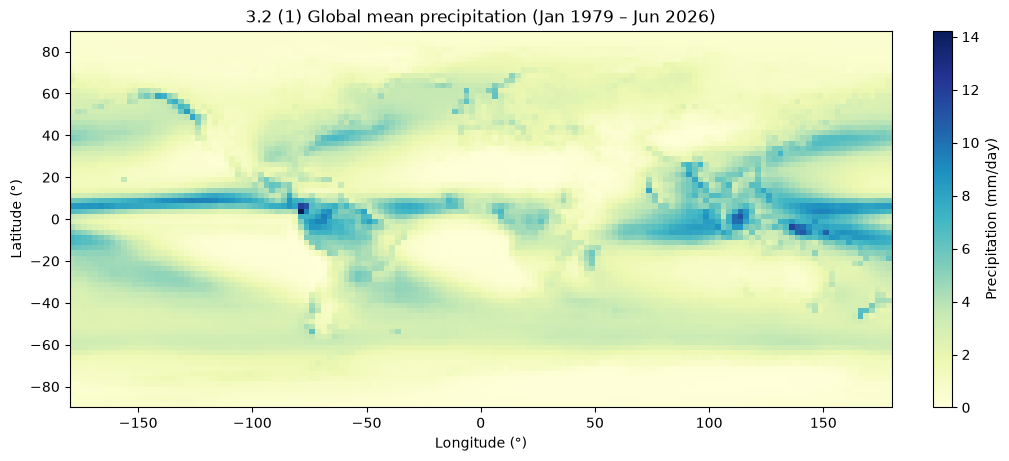

In [9]:
# 3.2绘制五种图探索数据

#图1：全球多年平均降水率分布

# 保留lat和lon两个维度对时间求平均
mean_map = precip.mean(dim="time")

fig, ax = plt.subplots(figsize=(10, 4.5), constrained_layout=True)

mean_map.plot.pcolormesh(
    ax=ax, x="lon", y="lat",
    cmap="YlGnBu", vmin=0,
    cbar_kwargs={"label": "Precipitation (mm/day)"}
)

ax.set(
    title="3.2 (1) Global mean precipitation (Jan 1979 – Jun 2026)",
    xlabel="Longitude (°)",
    ylabel="Latitude (°)"
)
plt.show()

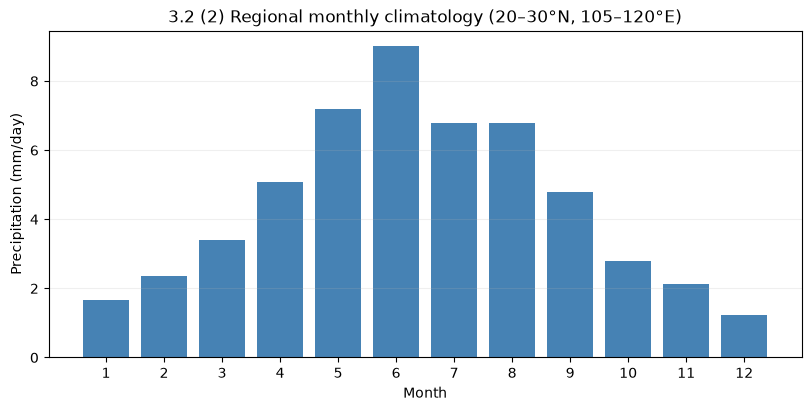

In [10]:
# 图2：区域逐月多年平均值柱状图

fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)

# 横轴是1～12月，纵轴是各月份的多年平均降水率
ax.bar(clim.month, clim, color="steelblue")

ax.set(
    title="3.2 (2) Regional monthly climatology (20–30°N, 105–120°E)",
    xlabel="Month",
    ylabel="Precipitation (mm/day)",
    xticks=range(1, 13)
)
ax.grid(axis="y", alpha=0.2)
plt.show()

年降水量最大年份及数值： 2016 1982.3 mm
年降水量最小年份及数值： 2003 1279.5 mm


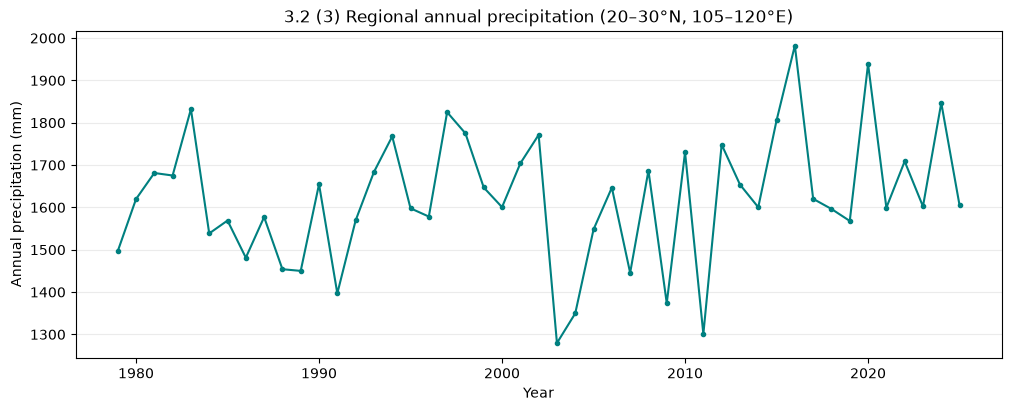

In [11]:
# 图3：区域平均年降水量时间序列

# mm/day × 当月天数 = 月累计降水量
monthly_total = regional_mean * regional_mean.time.dt.days_in_month

# 将同一年的各月份相加
annual_total = monthly_total.groupby("time.year").sum(dim="time")

# 统计每年有几个有效月份，只保留具有12个月数据都有效的年份
months_per_year = regional_mean.groupby("time.year").count(dim="time")
annual_total = annual_total.where(months_per_year == 12, drop=True)

print("年降水量最大年份及数值：", int(annual_total.idxmax().item()),
      round(annual_total.max().item(), 1), "mm")
print("年降水量最小年份及数值：", int(annual_total.idxmin().item()),
      round(annual_total.min().item(), 1), "mm")

fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
ax.plot(annual_total.year, annual_total, "o-", color="teal", markersize=3)

ax.set(
    title="3.2 (3) Regional annual precipitation (20–30°N, 105–120°E)",
    xlabel="Year",
    ylabel="Annual precipitation (mm)"
)
ax.grid(axis="y", alpha=0.25)
plt.show()

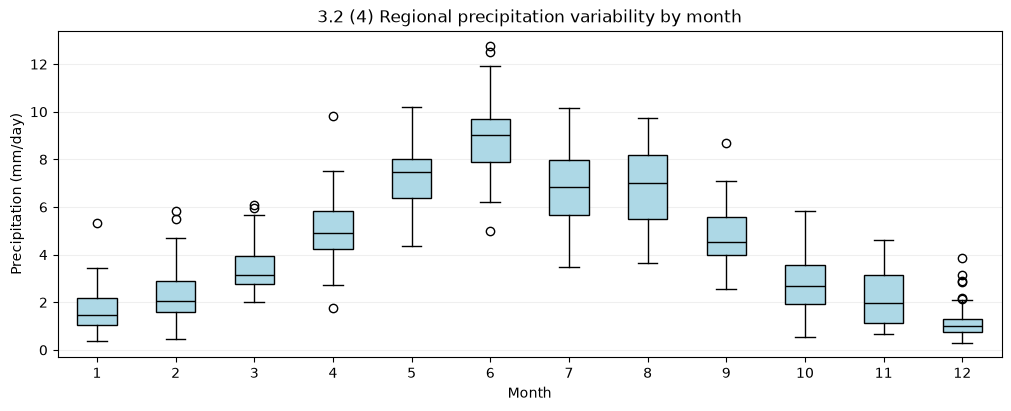

In [12]:
# 图4：各月份降水的箱线图

# 分别取出历年一月、二月一直到十二月的数据
box_data = []
for month in range(1, 13):
    values = regional_mean.where(
        regional_mean.time.dt.month == month,
        drop=True
    )
    box_data.append(values.values)

fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)

# 箱内横线表示中位数，箱体覆盖第25～75百分位
# 默认须线延伸至1.5倍四分位距范围内最远的数据点，超出须线范围的观测单独显示为圆点
ax.boxplot(
    box_data,
    patch_artist=True,
    boxprops={"facecolor": "lightblue"},
    medianprops={"color": "black"}
)

ax.set(
    title="3.2 (4) Regional precipitation variability by month",
    xlabel="Month",
    ylabel="Precipitation (mm/day)"
)
ax.grid(axis="y", alpha=0.2)
plt.show()

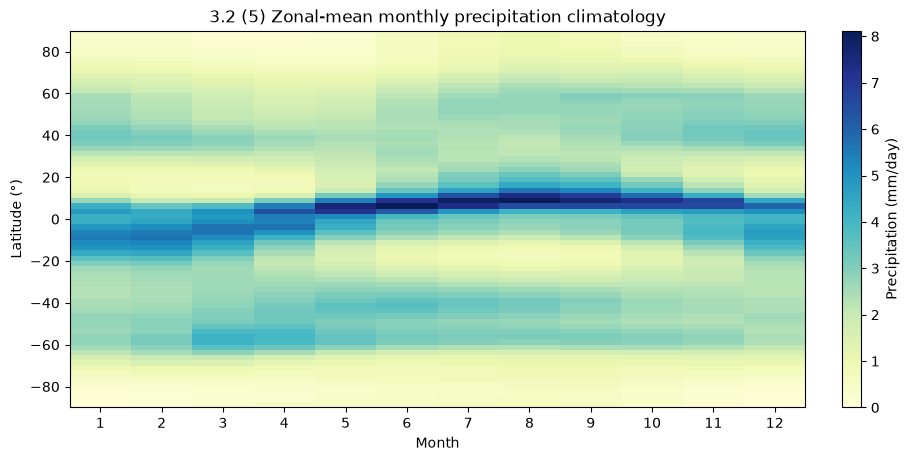

In [13]:
# 图5：纬度—月份降水气候态热力图

# 第一次平均后得到 month、lat、lon三个维度
# 第二次沿lon平均，最终保留month和lat
zonal_clim = (
    precip.groupby("time.month")
    .mean(dim="time")
    .mean(dim="lon")
)

fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)

zonal_clim.plot.pcolormesh(
    ax=ax, x="month", y="lat",
    cmap="YlGnBu", vmin=0,
    cbar_kwargs={"label": "Precipitation (mm/day)"}
)

ax.set(
    title="3.2 (5) Zonal-mean monthly precipitation climatology",
    xlabel="Month",
    ylabel="Latitude (°)",
    xticks=range(1, 13)
)
plt.show()